In [1]:
%load_ext  autoreload
%autoreload 2
%matplotlib inline

import os
import torch
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
import matplotlib.pyplot as plt
import numpy as np

import config
from utils import set_seed
from data_loader import get_dataloaders
from visualization import (
    visualize_eda, plot_metrics, visualize_predictions,
    plot_confusion_matrix_heatmap, plot_worst_predictions
)
from models import UniversalMLP, UniversalCNN
from dataset_strategies import FashionMNISTStrategy, CIFAR10Strategy
from trainer import (
    train_epoch, evaluate, ModelCheckpoint, EarlyStopping,
    get_all_predictions, generate_classification_report, get_worst_predictions
)

Random seed 873912

Data for Fashion-MNIST
[Fashion-MNIST] Train: 51000, Validation: 9000, Test: 10000


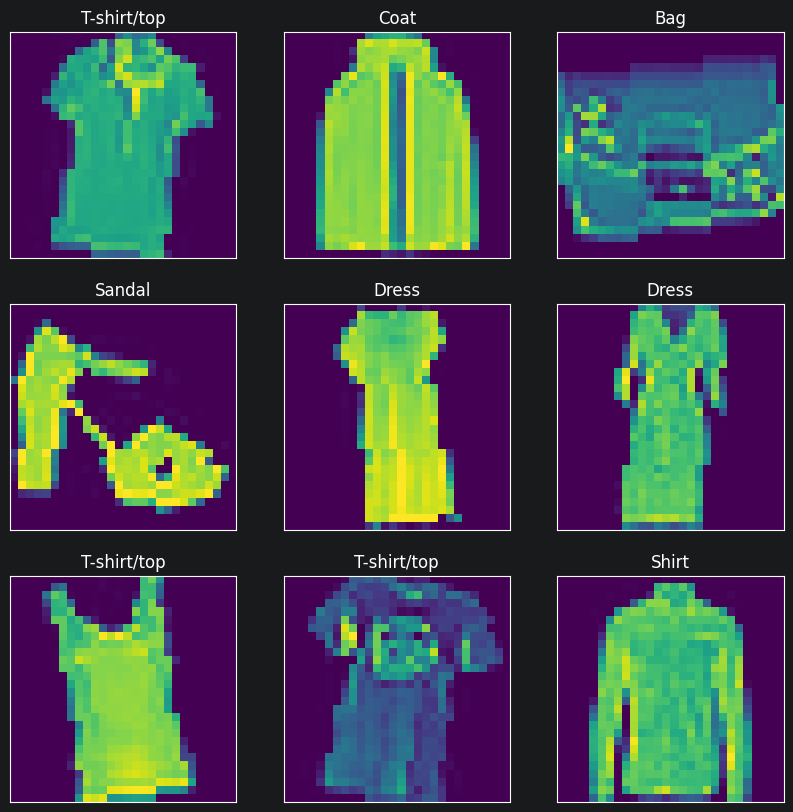


Data for CIFAR-10
[CIFAR-10] Train: 42500, Validation: 7500, Test: 10000


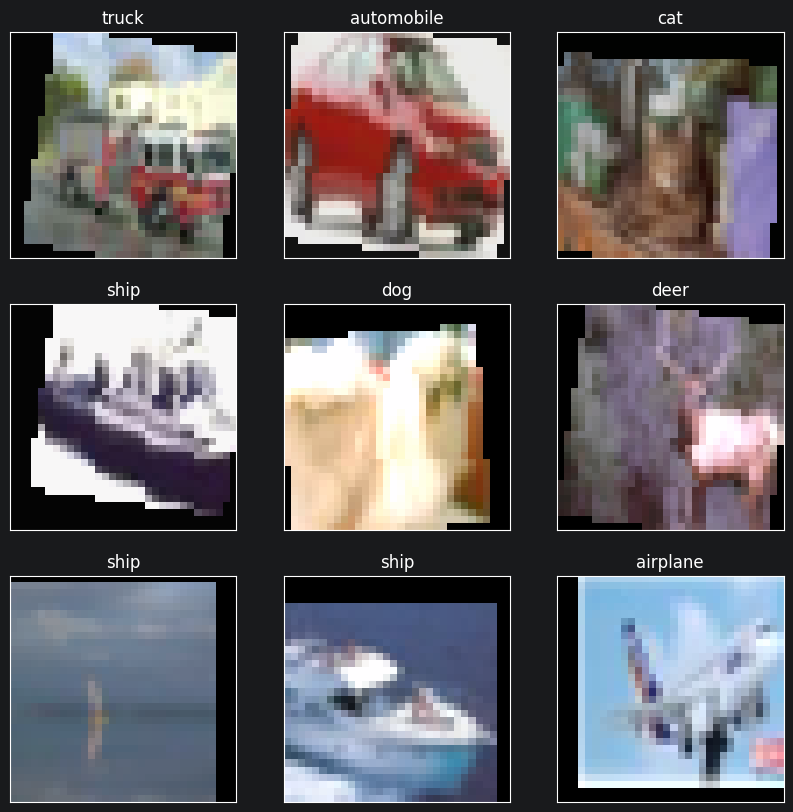

In [2]:
set_seed(config.RANDOM_SEED)

strategies = [FashionMNISTStrategy(), CIFAR10Strategy()]
dataloaders = {}

for strategy in strategies:
    print(f"\n{'='*50}\nData for {strategy.name}\n{'='*50}")
    train_loader, val_loader, test_loader = get_dataloaders(strategy)
    dataloaders[strategy.name] = (train_loader, val_loader, test_loader, strategy)
    visualize_eda(train_loader, strategy)

mlp_results = {}
cnn_results = {}


Training UniversalMLP: Fashion-MNIST
E 1/50 | LR: 0.001000 | Train Loss: 0.5959, Acc: 0.7822 | Val Loss: 0.4851, Acc: 0.8194
Validation accuracy improved to 0.8194. Saving model...
E 2/50 | LR: 0.001000 | Train Loss: 0.4658, Acc: 0.8289 | Val Loss: 0.4389, Acc: 0.8371
Validation accuracy improved to 0.8371. Saving model...
E 3/50 | LR: 0.001000 | Train Loss: 0.4448, Acc: 0.8361 | Val Loss: 0.4116, Acc: 0.8461
Validation accuracy improved to 0.8461. Saving model...
E 4/50 | LR: 0.001000 | Train Loss: 0.4244, Acc: 0.8441 | Val Loss: 0.4018, Acc: 0.8487
Validation accuracy improved to 0.8487. Saving model...
E 5/50 | LR: 0.001000 | Train Loss: 0.4109, Acc: 0.8475 | Val Loss: 0.3806, Acc: 0.8561
Validation accuracy improved to 0.8561. Saving model...
E 6/50 | LR: 0.001000 | Train Loss: 0.4044, Acc: 0.8502 | Val Loss: 0.3784, Acc: 0.8581
Validation accuracy improved to 0.8581. Saving model...
E 7/50 | LR: 0.001000 | Train Loss: 0.3981, Acc: 0.8534 | Val Loss: 0.3730, Acc: 0.8628
Validation

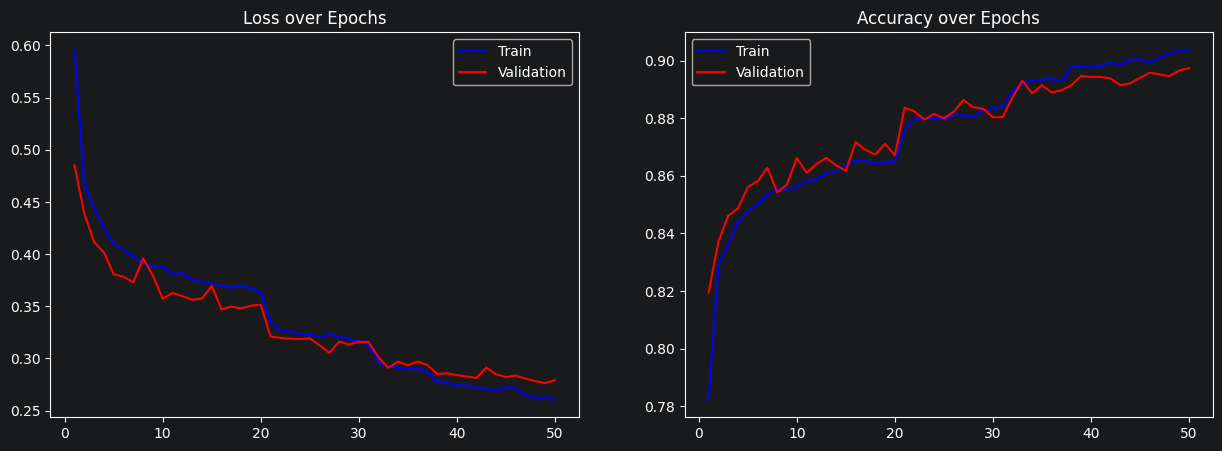

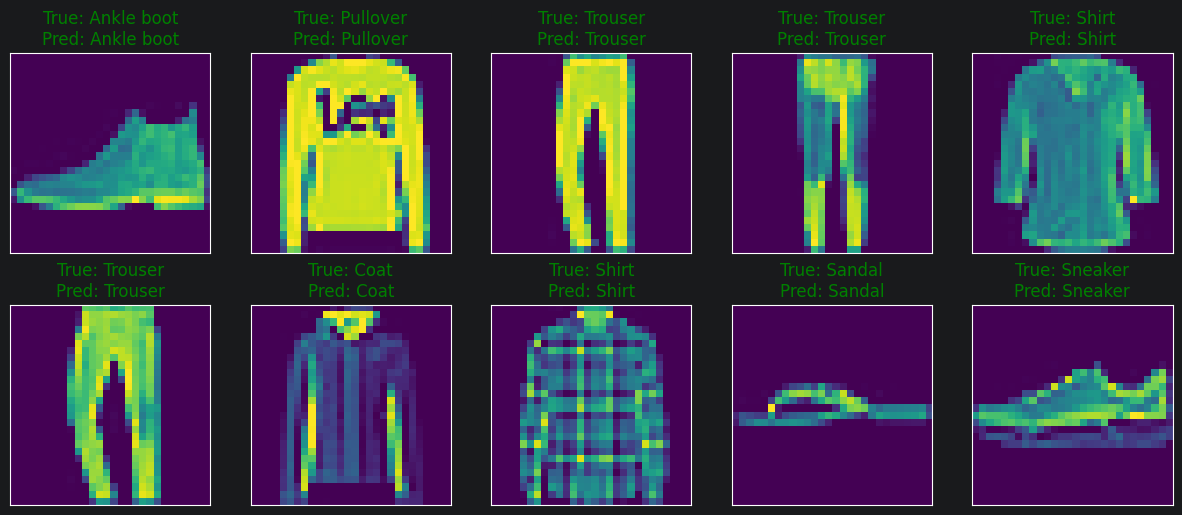

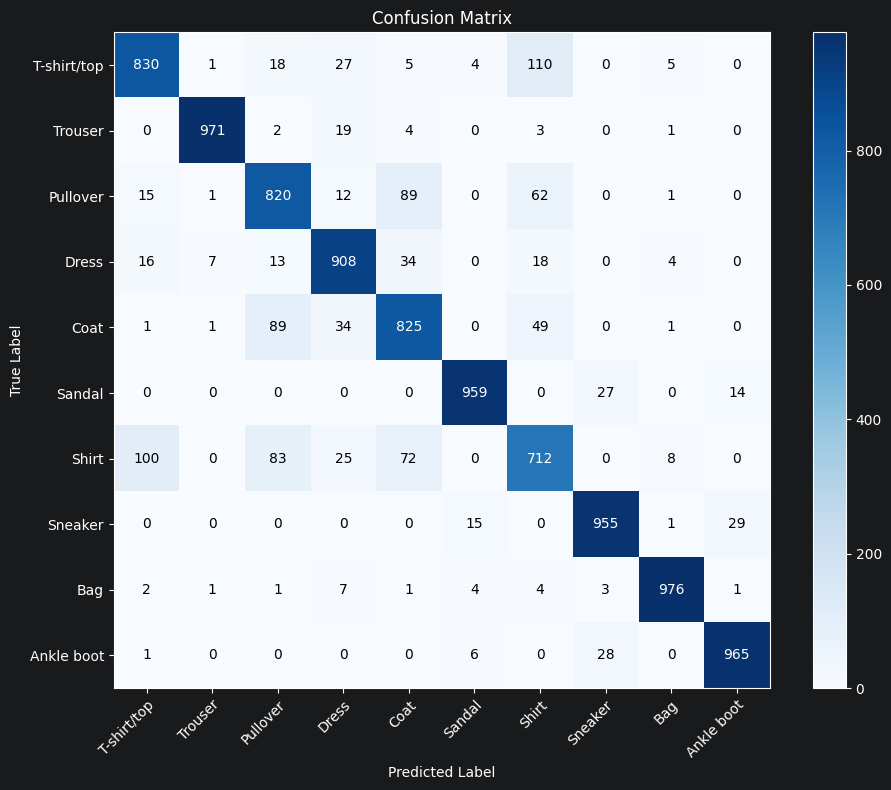


Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.86      0.83      0.84      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.80      0.82      0.81      1000
       Dress       0.88      0.91      0.89      1000
        Coat       0.80      0.82      0.81      1000
      Sandal       0.97      0.96      0.96      1000
       Shirt       0.74      0.71      0.73      1000
     Sneaker       0.94      0.95      0.95      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.96      0.96      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



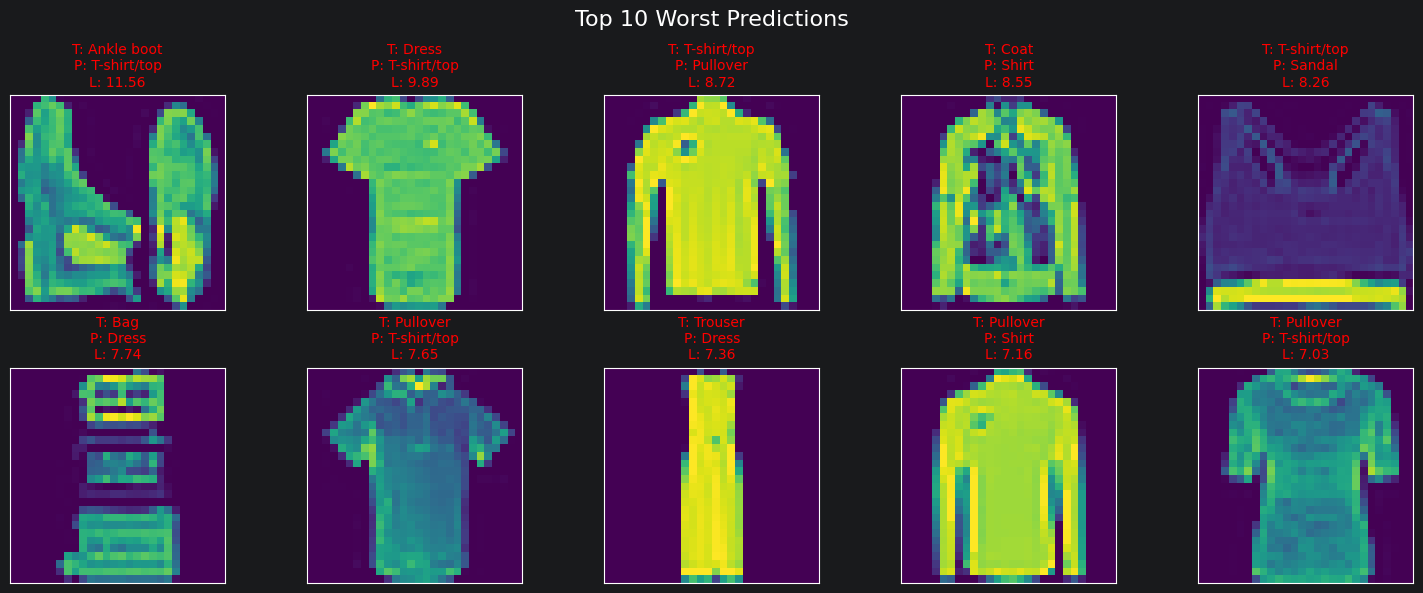


Training UniversalMLP: CIFAR-10
E 1/50 | LR: 0.001000 | Train Loss: 1.9172, Acc: 0.3001 | Val Loss: 1.8091, Acc: 0.3504
Validation accuracy improved to 0.3504. Saving model...
E 2/50 | LR: 0.001000 | Train Loss: 1.8070, Acc: 0.3494 | Val Loss: 1.7473, Acc: 0.3752
Validation accuracy improved to 0.3752. Saving model...
E 3/50 | LR: 0.001000 | Train Loss: 1.7580, Acc: 0.3649 | Val Loss: 1.6721, Acc: 0.3985
Validation accuracy improved to 0.3985. Saving model...
E 4/50 | LR: 0.001000 | Train Loss: 1.7364, Acc: 0.3729 | Val Loss: 1.6814, Acc: 0.3855
E 5/50 | LR: 0.001000 | Train Loss: 1.7105, Acc: 0.3841 | Val Loss: 1.6551, Acc: 0.4067
Validation accuracy improved to 0.4067. Saving model...
E 6/50 | LR: 0.001000 | Train Loss: 1.7026, Acc: 0.3880 | Val Loss: 1.6346, Acc: 0.4100
Validation accuracy improved to 0.4100. Saving model...
E 7/50 | LR: 0.001000 | Train Loss: 1.6881, Acc: 0.3928 | Val Loss: 1.6518, Acc: 0.4100
E 8/50 | LR: 0.001000 | Train Loss: 1.7017, Acc: 0.3871 | Val Loss: 1.6

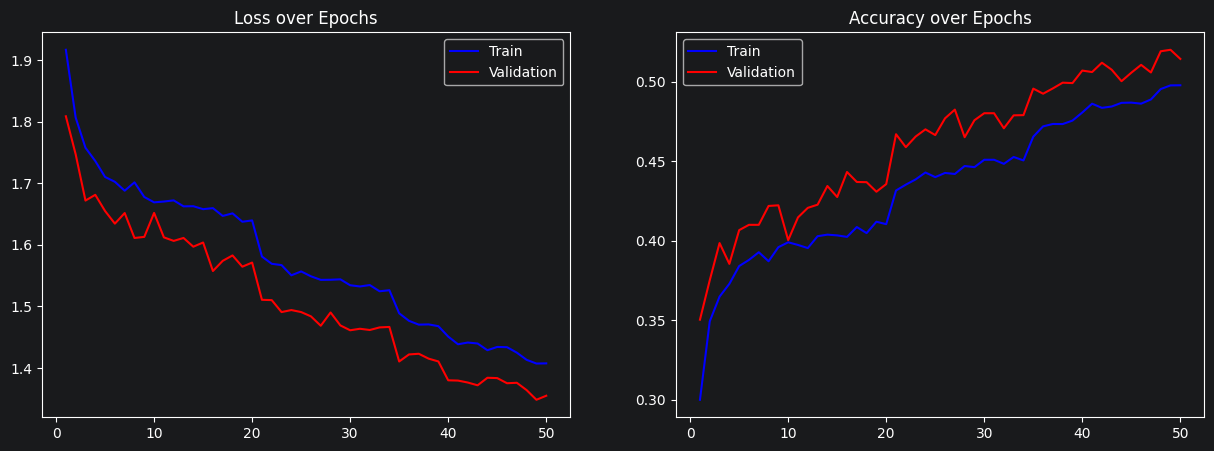

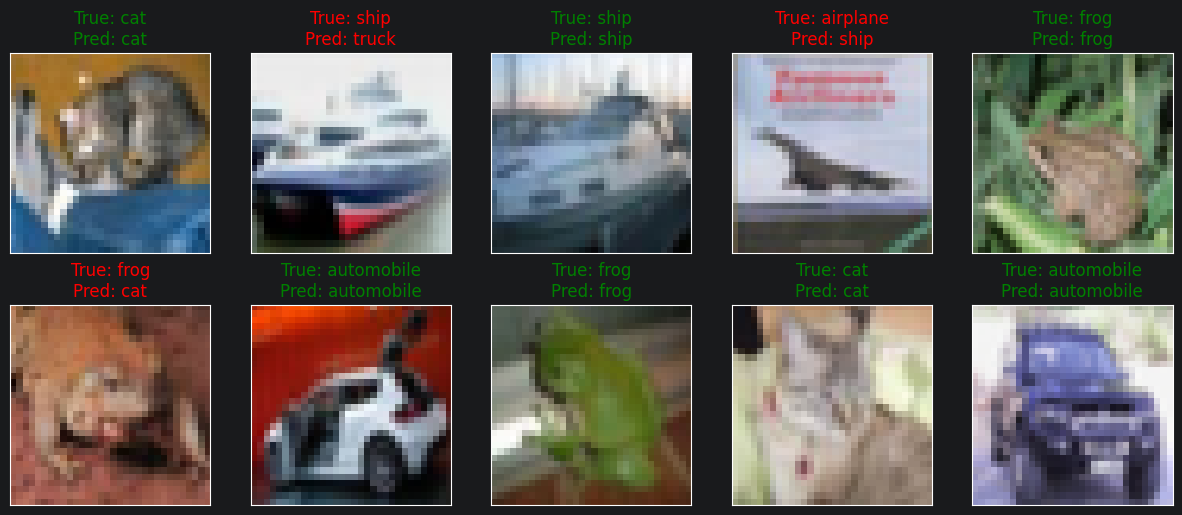

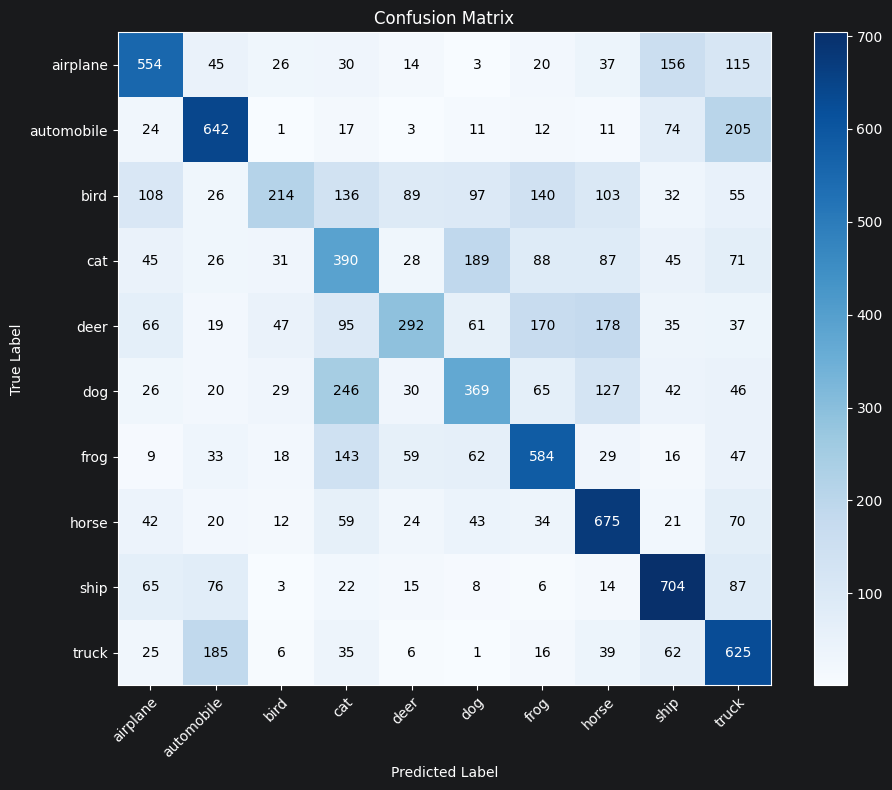


Classification Report:
              precision    recall  f1-score   support

    airplane       0.57      0.55      0.56      1000
  automobile       0.59      0.64      0.61      1000
        bird       0.55      0.21      0.31      1000
         cat       0.33      0.39      0.36      1000
        deer       0.52      0.29      0.37      1000
         dog       0.44      0.37      0.40      1000
        frog       0.51      0.58      0.55      1000
       horse       0.52      0.68      0.59      1000
        ship       0.59      0.70      0.64      1000
       truck       0.46      0.62      0.53      1000

    accuracy                           0.50     10000
   macro avg       0.51      0.50      0.49     10000
weighted avg       0.51      0.50      0.49     10000



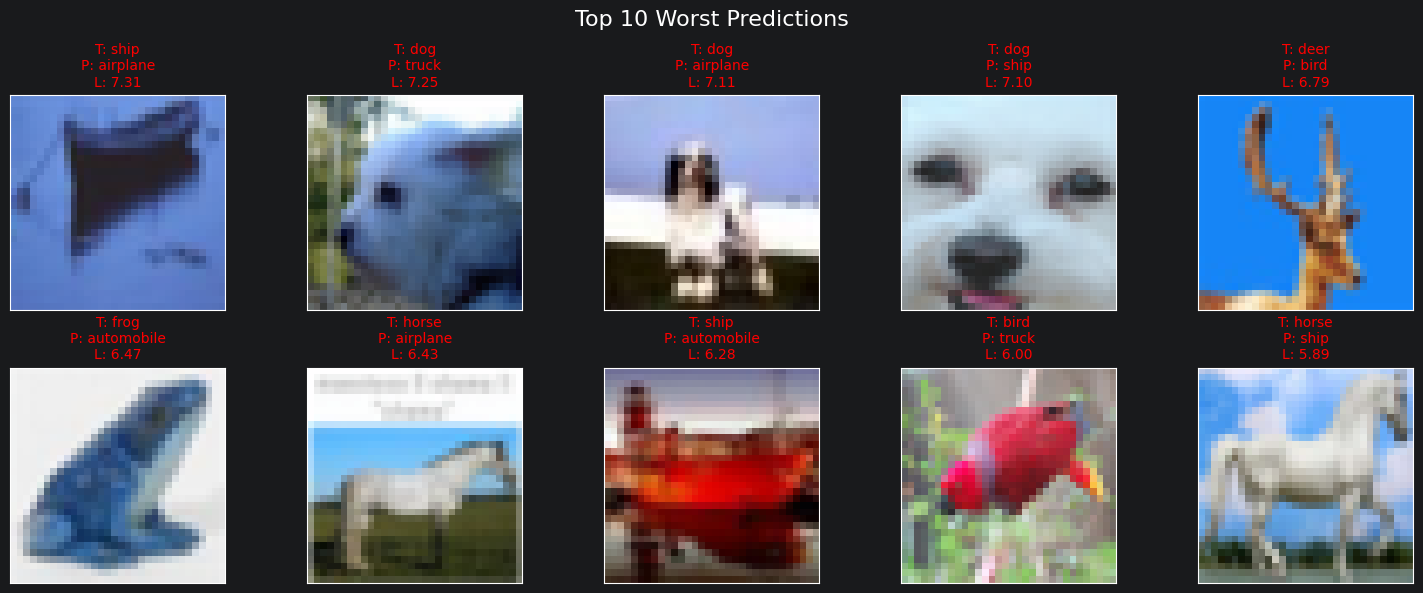

In [3]:
for name, (train_loader, val_loader, test_loader, strategy) in dataloaders.items():
    print(f"\n{'='*50}\nTraining UniversalMLP: {name}\n{'='*50}")

    model_mlp = UniversalMLP(in_features=strategy.in_features, num_classes=strategy.num_classes).to(config.DEVICE)

    criterion = nn.CrossEntropyLoss()
    optimizer_mlp = optim.Adam(model_mlp.parameters(), lr=config.LEARNING_RATE, weight_decay=config.WEIGHT_DECAY)
    scheduler_mlp = lr_scheduler.ReduceLROnPlateau(optimizer_mlp, mode='min', factor=0.5, patience=3)
    checkpoint_mlp = ModelCheckpoint(f'best_mlp_{name}.pth')
    early_stopping_mlp = EarlyStopping(patience=config.PATIENCE)

    train_losses_mlp, val_losses_mlp, train_accs_mlp, val_accs_mlp = [], [], [], []

    for epoch in range(config.EPOCHS):
        train_loss, train_acc = train_epoch(model_mlp, train_loader, criterion, optimizer_mlp, config.DEVICE)
        val_loss, val_acc = evaluate(model_mlp, val_loader, criterion, config.DEVICE)

        scheduler_mlp.step(val_loss)
        early_stopping_mlp(val_loss)

        train_losses_mlp.append(train_loss)
        val_losses_mlp.append(val_loss)
        train_accs_mlp.append(train_acc)
        val_accs_mlp.append(val_acc)

        current_lr = optimizer_mlp.param_groups[0]['lr']
        print(f"E {epoch+1}/{config.EPOCHS} | LR: {current_lr:.6f} | Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f}, Acc: {val_acc:.4f}")
        checkpoint_mlp(model_mlp, val_acc)

        if early_stopping_mlp.early_stop:
            print("Early Stopping was activated!")
            break

    model_mlp.load_state_dict(torch.load(f'best_mlp_{name}.pth', weights_only=True))
    test_loss_mlp, test_acc_mlp = evaluate(model_mlp, test_loader, criterion, config.DEVICE)
    print(f"\nFinal results (Test Set - {name}): Loss: {test_loss_mlp:.4f}, Acc: {test_acc_mlp:.4f}")

    mlp_results[name] = test_acc_mlp

    plot_metrics(train_losses_mlp, val_losses_mlp, train_accs_mlp, val_accs_mlp)
    visualize_predictions(model_mlp, test_loader, strategy, config.DEVICE)

    true_labels, pred_labels = get_all_predictions(model_mlp, test_loader, config.DEVICE)
    plot_confusion_matrix_heatmap(true_labels, pred_labels, strategy.classes)
    generate_classification_report(true_labels, pred_labels, strategy.classes)

    worst_images, worst_trues, worst_preds, worst_losses = get_worst_predictions(model_mlp, test_loader, config.DEVICE)
    plot_worst_predictions(worst_images, worst_trues, worst_preds, worst_losses, strategy)


Training UniversalCNN: Fashion-MNIST
E 1/50 | LR: 0.001000 | Train Loss: 0.5303, Acc: 0.8076 | Val Loss: 0.3675, Acc: 0.8664
Validation accuracy improved to 0.8664. Saving model...
E 2/50 | LR: 0.001000 | Train Loss: 0.3634, Acc: 0.8686 | Val Loss: 0.3101, Acc: 0.8852
Validation accuracy improved to 0.8852. Saving model...
E 3/50 | LR: 0.001000 | Train Loss: 0.3180, Acc: 0.8835 | Val Loss: 0.2846, Acc: 0.8934
Validation accuracy improved to 0.8934. Saving model...
E 4/50 | LR: 0.001000 | Train Loss: 0.2971, Acc: 0.8944 | Val Loss: 0.2795, Acc: 0.8982
Validation accuracy improved to 0.8982. Saving model...
E 5/50 | LR: 0.001000 | Train Loss: 0.2839, Acc: 0.8973 | Val Loss: 0.2598, Acc: 0.9019
Validation accuracy improved to 0.9019. Saving model...
E 6/50 | LR: 0.001000 | Train Loss: 0.2700, Acc: 0.9020 | Val Loss: 0.2442, Acc: 0.9123
Validation accuracy improved to 0.9123. Saving model...
E 7/50 | LR: 0.001000 | Train Loss: 0.2615, Acc: 0.9055 | Val Loss: 0.2673, Acc: 0.9018
E 8/50 | L

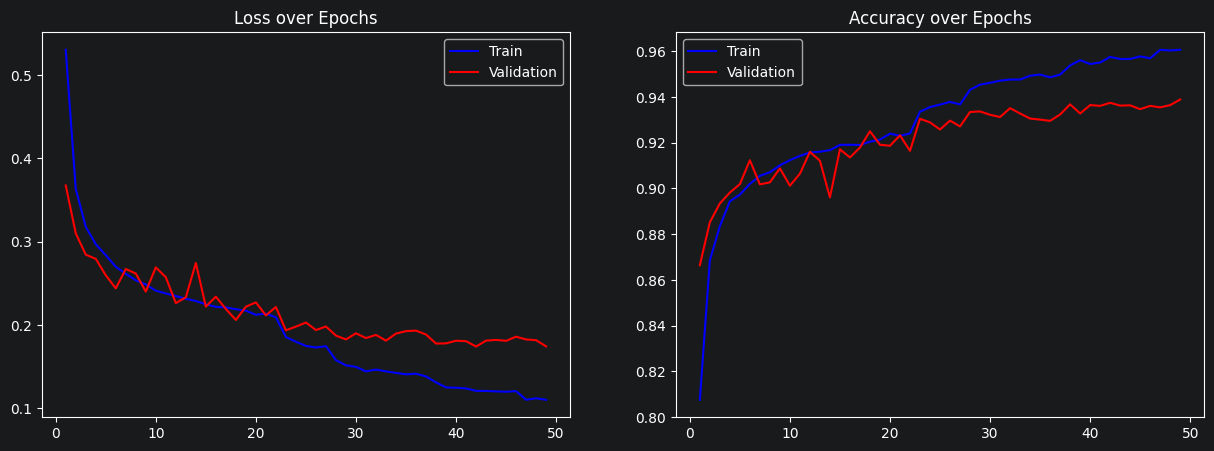

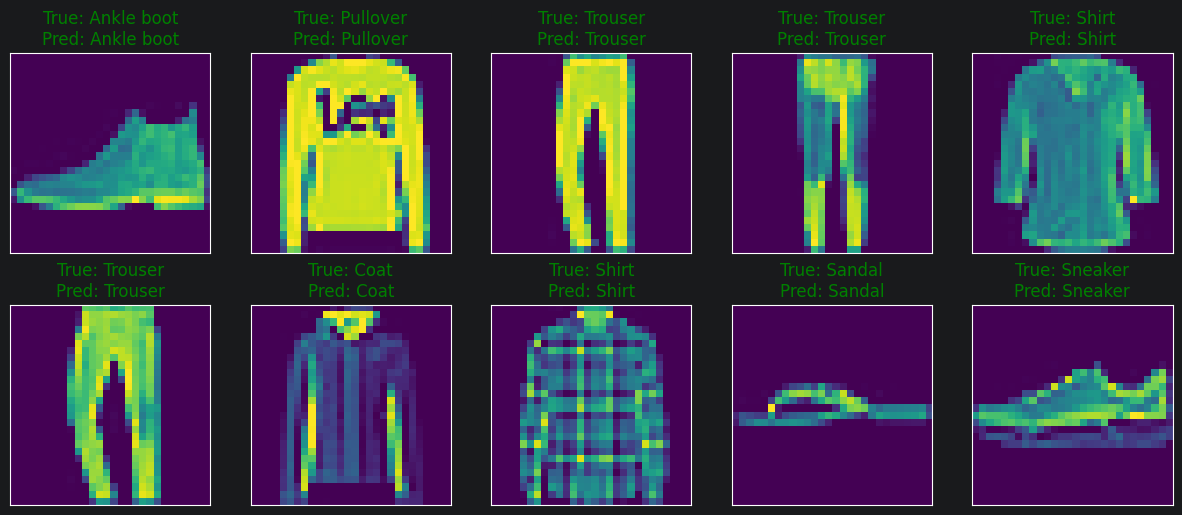

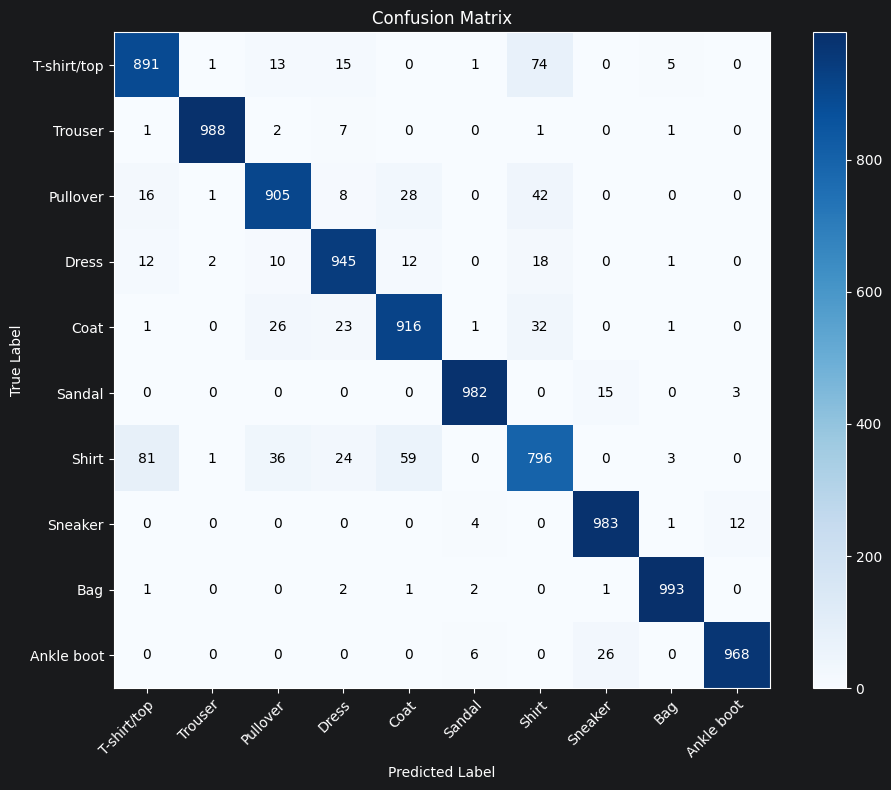


Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.89      0.89      0.89      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.91      0.91      0.91      1000
       Dress       0.92      0.94      0.93      1000
        Coat       0.90      0.92      0.91      1000
      Sandal       0.99      0.98      0.98      1000
       Shirt       0.83      0.80      0.81      1000
     Sneaker       0.96      0.98      0.97      1000
         Bag       0.99      0.99      0.99      1000
  Ankle boot       0.98      0.97      0.98      1000

    accuracy                           0.94     10000
   macro avg       0.94      0.94      0.94     10000
weighted avg       0.94      0.94      0.94     10000



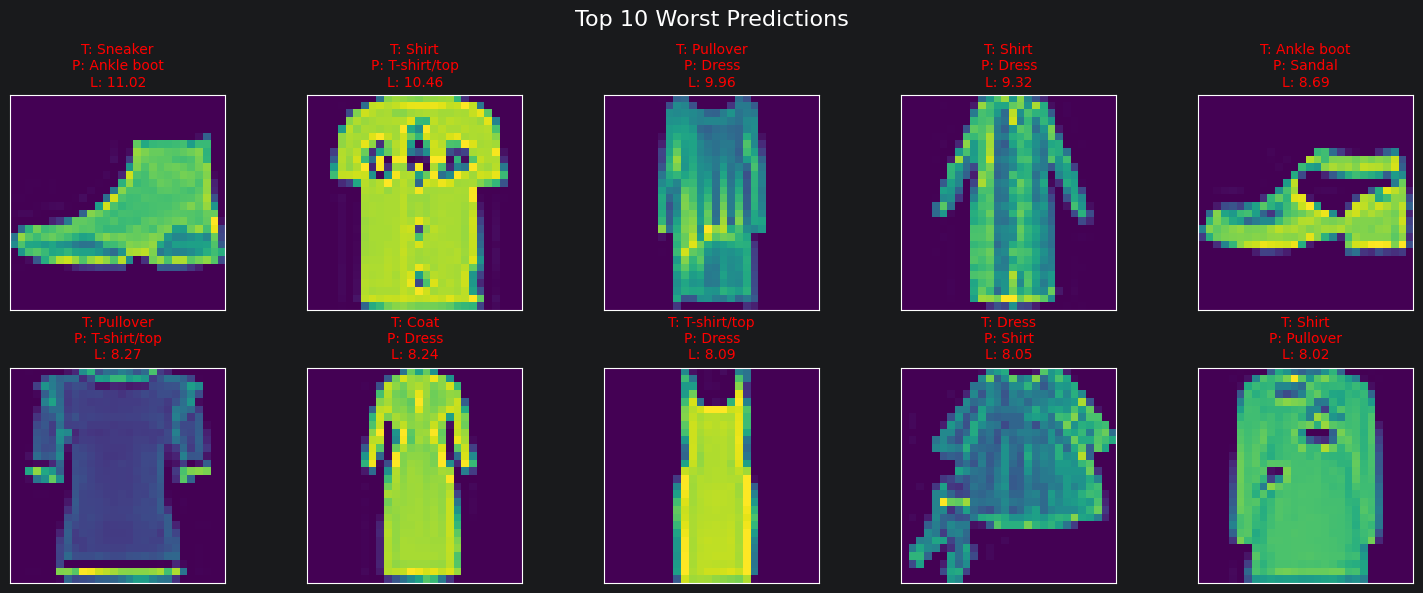


Training UniversalCNN: CIFAR-10
E 1/50 | LR: 0.001000 | Train Loss: 1.6273, Acc: 0.4002 | Val Loss: 1.5319, Acc: 0.4352
Validation accuracy improved to 0.4352. Saving model...
E 2/50 | LR: 0.001000 | Train Loss: 1.3473, Acc: 0.5082 | Val Loss: 1.2291, Acc: 0.5523
Validation accuracy improved to 0.5523. Saving model...
E 3/50 | LR: 0.001000 | Train Loss: 1.2207, Acc: 0.5628 | Val Loss: 1.3208, Acc: 0.5444
E 4/50 | LR: 0.001000 | Train Loss: 1.1734, Acc: 0.5834 | Val Loss: 1.0637, Acc: 0.6279
Validation accuracy improved to 0.6279. Saving model...
E 5/50 | LR: 0.001000 | Train Loss: 1.0982, Acc: 0.6116 | Val Loss: 1.1253, Acc: 0.5985
E 6/50 | LR: 0.001000 | Train Loss: 1.0456, Acc: 0.6308 | Val Loss: 0.9625, Acc: 0.6581
Validation accuracy improved to 0.6581. Saving model...
E 7/50 | LR: 0.001000 | Train Loss: 1.0154, Acc: 0.6427 | Val Loss: 0.9407, Acc: 0.6645
Validation accuracy improved to 0.6645. Saving model...
E 8/50 | LR: 0.001000 | Train Loss: 0.9731, Acc: 0.6583 | Val Loss: 0.9

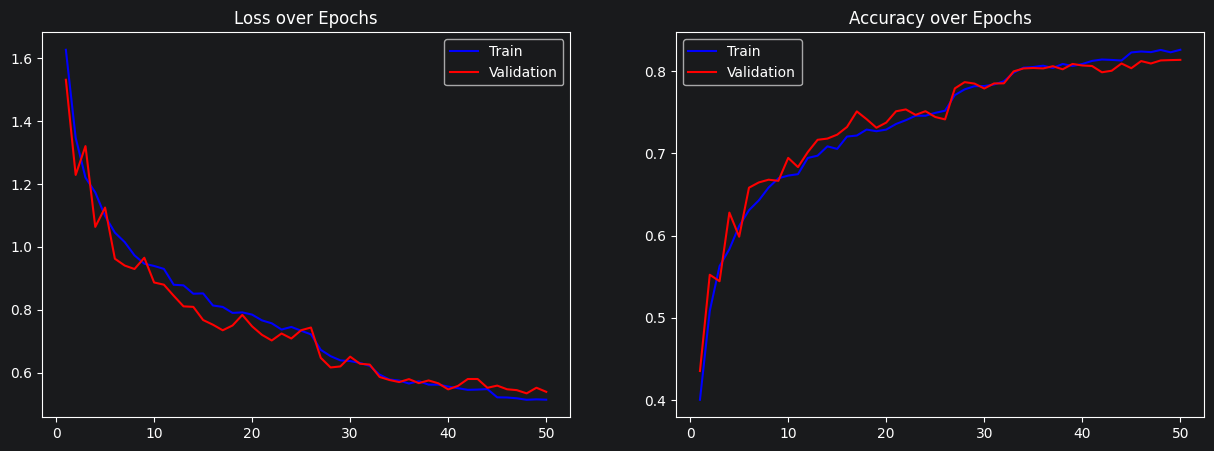

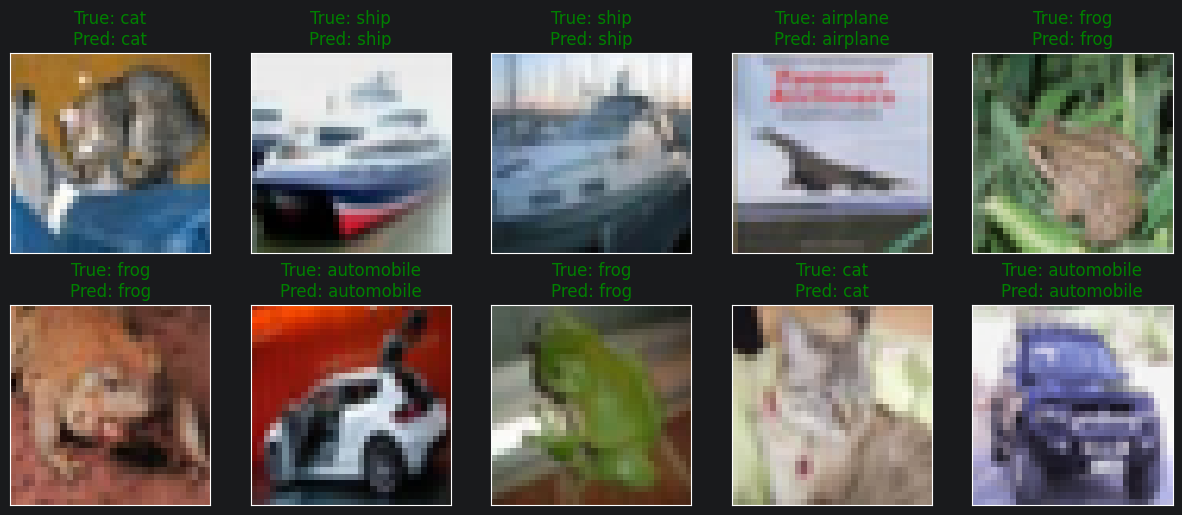

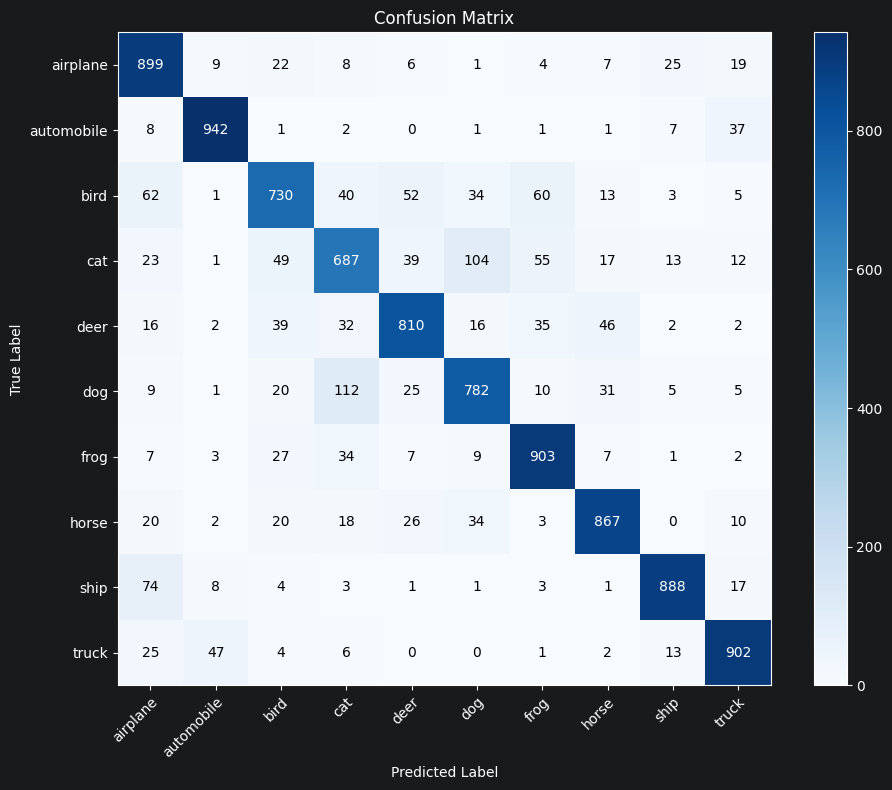


Classification Report:
              precision    recall  f1-score   support

    airplane       0.79      0.90      0.84      1000
  automobile       0.93      0.94      0.93      1000
        bird       0.80      0.73      0.76      1000
         cat       0.73      0.69      0.71      1000
        deer       0.84      0.81      0.82      1000
         dog       0.80      0.78      0.79      1000
        frog       0.84      0.90      0.87      1000
       horse       0.87      0.87      0.87      1000
        ship       0.93      0.89      0.91      1000
       truck       0.89      0.90      0.90      1000

    accuracy                           0.84     10000
   macro avg       0.84      0.84      0.84     10000
weighted avg       0.84      0.84      0.84     10000



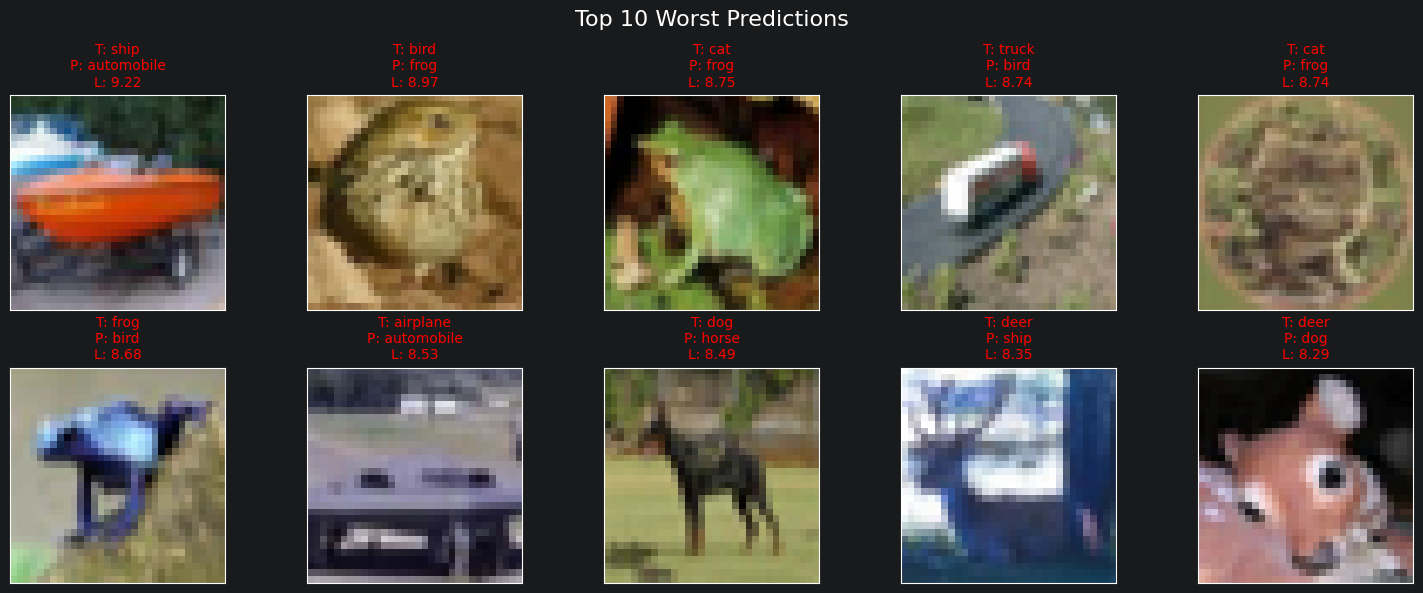

In [4]:
for name, (train_loader, val_loader, test_loader, strategy) in dataloaders.items():
    print(f"\n{'='*50}\nTraining UniversalCNN: {name}\n{'='*50}")

    model_cnn = UniversalCNN(in_channels=strategy.in_channels, flatten_dim=strategy.cnn_flatten_dim, num_classes=strategy.num_classes).to(config.DEVICE)

    criterion = nn.CrossEntropyLoss()
    optimizer_cnn = optim.Adam(model_cnn.parameters(), lr=config.LEARNING_RATE, weight_decay=config.WEIGHT_DECAY)
    scheduler_cnn = lr_scheduler.ReduceLROnPlateau(optimizer_cnn, mode='min', factor=0.5, patience=3)
    checkpoint_cnn = ModelCheckpoint(f'best_cnn_{name}.pth')
    early_stopping_cnn = EarlyStopping(patience=config.PATIENCE)

    train_losses_cnn, val_losses_cnn, train_accs_cnn, val_accs_cnn = [], [], [], []

    for epoch in range(config.EPOCHS):
        train_loss, train_acc = train_epoch(model_cnn, train_loader, criterion, optimizer_cnn, config.DEVICE)
        val_loss, val_acc = evaluate(model_cnn, val_loader, criterion, config.DEVICE)

        scheduler_cnn.step(val_loss)
        early_stopping_cnn(val_loss)

        train_losses_cnn.append(train_loss)
        val_losses_cnn.append(val_loss)
        train_accs_cnn.append(train_acc)
        val_accs_cnn.append(val_acc)

        current_lr = optimizer_cnn.param_groups[0]['lr']
        print(f"E {epoch+1}/{config.EPOCHS} | LR: {current_lr:.6f} | Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f}, Acc: {val_acc:.4f}")
        checkpoint_cnn(model_cnn, val_acc)

        if early_stopping_cnn.early_stop:
            print("Early Stopping was activated!")
            break

    model_cnn.load_state_dict(torch.load(f'best_cnn_{name}.pth', weights_only=True))
    test_loss_cnn, test_acc_cnn = evaluate(model_cnn, test_loader, criterion, config.DEVICE)
    print(f"\nFinal results (Test Set - {name}): Loss: {test_loss_cnn:.4f}, Acc: {test_acc_cnn:.4f}")

    cnn_results[name] = test_acc_cnn

    plot_metrics(train_losses_cnn, val_losses_cnn, train_accs_cnn, val_accs_cnn)
    visualize_predictions(model_cnn, test_loader, strategy, config.DEVICE)

    true_labels, pred_labels = get_all_predictions(model_cnn, test_loader, config.DEVICE)
    plot_confusion_matrix_heatmap(true_labels, pred_labels, strategy.classes)
    generate_classification_report(true_labels, pred_labels, strategy.classes)

    worst_images, worst_trues, worst_preds, worst_losses = get_worst_predictions(model_cnn, test_loader, config.DEVICE)
    plot_worst_predictions(worst_images, worst_trues, worst_preds, worst_losses, strategy)


Results

Dataset: Fashion-MNIST
  - UniversalMLP Test Acc: 89.21%
  - UniversalCNN Test Acc: 93.67%
  --> CNN is better by 4.46 percentage points

Dataset: CIFAR-10
  - UniversalMLP Test Acc: 50.49%
  - UniversalCNN Test Acc: 84.10%
  --> CNN is better by 33.61 percentage points


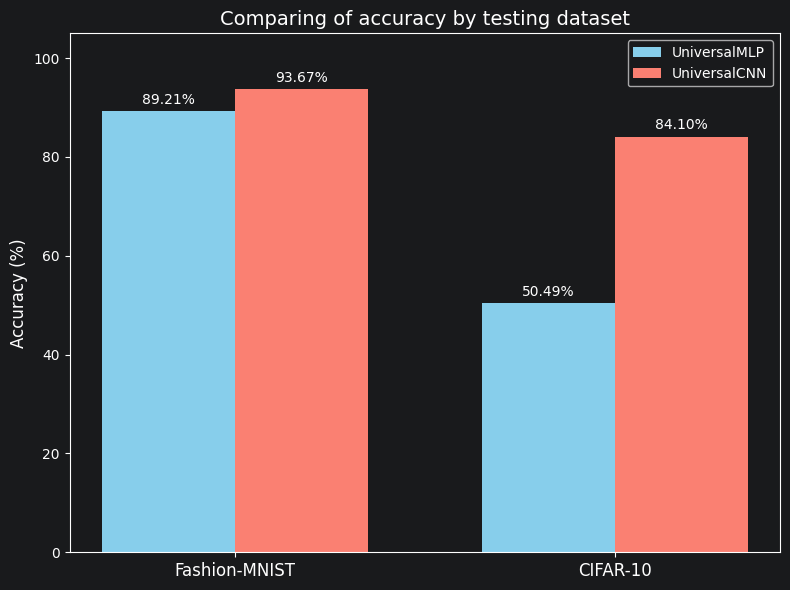

In [5]:
print(f"\n{'='*50}\nResults\n{'='*50}")

if not mlp_results or not cnn_results: print("Attention: the data are incomplete or corrupted. Make sure, you have ran the MLP and CNN cell at lest once")
else:
    datasets = list(dataloaders.keys())
    mlp_scores = []
    cnn_scores = []

    for name in datasets:
        mlp_acc = mlp_results.get(name, 0.0) * 100
        cnn_acc = cnn_results.get(name, 0.0) * 100
        mlp_scores.append(mlp_acc)
        cnn_scores.append(cnn_acc)

        print(f"\nDataset: {name}")
        print(f"  - UniversalMLP Test Acc: {mlp_acc:.2f}%")
        print(f"  - UniversalCNN Test Acc: {cnn_acc:.2f}%")

        diff = cnn_acc - mlp_acc
        if diff > 0: print(f"  --> CNN is better by {diff:.2f} percentage points")
        elif diff < 0: print(f"  --> MLP is better by {abs(diff):.2f} percentage points")
        else: print(f"  --> Models shown the same results")

    x = np.arange(len(datasets))
    width = 0.35

    fig, ax = plt.subplots(figsize=(8, 6))
    rects1 = ax.bar(x - width/2, mlp_scores, width, label='UniversalMLP', color='skyblue')
    rects2 = ax.bar(x + width/2, cnn_scores, width, label='UniversalCNN', color='salmon')

    ax.set_ylabel('Accuracy (%)', fontsize=12)
    ax.set_title('Comparing of accuracy by testing dataset', fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(datasets, fontsize=12)
    ax.set_ylim(0, 105)
    ax.legend()

    ax.bar_label(rects1, padding=3, fmt='%.2f%%')
    ax.bar_label(rects2, padding=3, fmt='%.2f%%')

    fig.tight_layout()
    plt.show()